# Comparación de modelos, selección y conclusiones

### Entorno y persistencia de resultados

En la celda siguiente fijé tres cosas que condicionan la reproducibilidad del experimento.

**Semilla fija.** Usé `RANDOM_STATE = 42` en la partición train/test y en el ajuste de todos los
modelos. Sin ella, cada ejecución produciría particiones distintas y las métricas no serían
comparables entre corridas ni verificables por un tercero.

**Persistencia en Google Drive.** Escribí los resultados en `MyDrive/bank_marketing` y no en el
disco temporal de Colab, que se borra al cerrar la sesión. El notebook 03 deja las particiones
preparadas y los notebooks 04 y 05 las consumen tal cual, de modo que todos operan sobre exactamente
los mismos datos. Si el montaje no se completa, la celda interrumpe la ejecución en lugar de escribir
en una ubicación volátil. Fuera de Colab no hace falta Drive, y los resultados se escriben en la
carpeta del repositorio (los gráficos en `splits/`).

**Registro de las figuras.** La función `guardar` escribe cada gráfico en `splits/` como PNG a 200
dpi. La invoco antes de `plt.show()`, porque mostrar la figura vacía el buffer de matplotlib y el
archivo saldría en blanco.

In [1]:
import os, io, time, json, zipfile, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError(
            "Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso "
            "en la ventana emergente."
        )
    RUTA = "/content/drive/MyDrive/bank_marketing"
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")

CARPETA_SPLITS = os.path.join(RUTA, "splits")
os.makedirs(CARPETA_SPLITS, exist_ok=True)

def guardar(nombre):
    destino = os.path.join(CARPETA_SPLITS, nombre + ".png")
    plt.savefig(destino, dpi=200, bbox_inches="tight", facecolor="white")
    print("Gráfico guardado:", destino)

print("Guardando en Google Drive" if EN_DRIVE else "Google Drive no disponible: guardando localmente")
print("Ruta de trabajo:", RUTA)

Google Drive no disponible: guardando localmente
Ruta de trabajo: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing


## Carga de resultados

Leí `resultados_modelos.json` (una entrada por modelo), `puntajes_test.npz` (el puntaje que cada modelo
asignó a cada cliente de prueba, necesario para las curvas ROC) y `entorno.json` (la máquina donde se
midieron los tiempos). En este notebook no entrené nada, de modo que la tabla, las figuras y la selección
salen de los mismos archivos y no pueden contradecirse entre sí. Si falta alguno de los archivos, el
notebook 04 no se ejecutó completo.

In [2]:
from sklearn.metrics import roc_curve, roc_auc_score, ConfusionMatrixDisplay

with open(os.path.join(RUTA, "resultados_modelos.json"), encoding="utf-8") as f:
    resultados = json.load(f)
puntajes = np.load(os.path.join(RUTA, "puntajes_test.npz"))
with open(os.path.join(RUTA, "entorno.json"), encoding="utf-8") as f:
    entorno = json.load(f)
y_test = puntajes["y_test"]

nombres = {"SVM": "SVM", "Arbol": "Árbol de decisión", "RandomForest": "Random Forest", "XGBoost": "XGBoost"}
colores = {"SVM": "#2a6f97", "Arbol": "#c8553d", "RandomForest": "#3a7d44", "XGBoost": "#7b2d8e"}
modelos = list(nombres)
print("Modelos cargados:", list(resultados))
print("Clientes de prueba:", len(y_test), "| contratadores:", int(y_test.sum()))
print("Entorno de medición:", entorno["procesador"], "|", entorno["nucleos_logicos"], "núcleos lógicos |",
      entorno["memoria_gb"], "GB de memoria | scikit-learn", entorno["scikit_learn"], "| xgboost", entorno["xgboost"])

Modelos cargados: ['Baseline', 'SVM', 'Arbol', 'RandomForest', 'XGBoost']
Clientes de prueba: 9043 | contratadores: 1058
Entorno de medición: Intel64 Family 6 Model 154 Stepping 3, GenuineIntel | 16 núcleos lógicos | 31.7 GB de memoria | scikit-learn 1.8.0 | xgboost 3.4.1


## Tabla comparativa

Armé la tabla con las cinco métricas de rendimiento sobre el conjunto de prueba y los dos tiempos
(medianas de varias repeticiones). Mostré la línea base aparte, como piso de referencia, y guardé la tabla
como CSV para el informe, con el rango de los tiempos incluido.

In [3]:
def fila(clave):
    r = resultados[clave]
    return {"accuracy": r["test"]["accuracy"], "precision": r["test"]["precision"], "recall": r["test"]["recall"],
            "f1": r["test"]["f1"], "roc_auc": r["test"]["roc_auc"],
            "t_entrenamiento_s": r["tiempo_entrenamiento_s"], "t_prediccion_s": r["tiempo_prediccion_s"],
            "t_entrenamiento_min_s": r.get("rango_entrenamiento_s", [np.nan, np.nan])[0],
            "t_entrenamiento_max_s": r.get("rango_entrenamiento_s", [np.nan, np.nan])[1],
            "t_prediccion_min_s": r["rango_prediccion_s"][0], "t_prediccion_max_s": r["rango_prediccion_s"][1]}

tabla = pd.DataFrame({nombres[k]: fila(k) for k in modelos}).T
tabla.index.name = "modelo"
tabla.round(4).to_csv(os.path.join(RUTA, "tabla_comparativa.csv"))
print(tabla[["accuracy", "precision", "recall", "f1", "roc_auc", "t_entrenamiento_s", "t_prediccion_s"]].round(
    {"accuracy": 4, "precision": 4, "recall": 4, "f1": 4, "roc_auc": 4, "t_entrenamiento_s": 2, "t_prediccion_s": 3}).to_string())
print("\nRango de los tiempos (mínimo y máximo de las repeticiones, en segundos):")
print(tabla[["t_entrenamiento_min_s", "t_entrenamiento_max_s", "t_prediccion_min_s", "t_prediccion_max_s"]].round(3).to_string())
print("\nLínea base (siempre 'no'):")
print(pd.Series(fila("Baseline")).round(4).to_string())

                   accuracy  precision  recall      f1  roc_auc  t_entrenamiento_s  t_prediccion_s
modelo                                                                                            
SVM                  0.8276     0.3573  0.5926  0.4458   0.7898             135.27          18.507
Árbol de decisión    0.8143     0.3358  0.6002  0.4307   0.7800               0.60           0.050
Random Forest        0.8732     0.4621  0.5132  0.4863   0.8043             113.92           0.551
XGBoost              0.8246     0.3576  0.6267  0.4554   0.8039               2.57           0.158

Rango de los tiempos (mínimo y máximo de las repeticiones, en segundos):
                   t_entrenamiento_min_s  t_entrenamiento_max_s  t_prediccion_min_s  t_prediccion_max_s
modelo                                                                                                 
SVM                              125.120                155.829              18.389              20.397
Árbol de decisión   

**Lectura.** La tabla resume el experimento. En rendimiento, el Random Forest queda primero en F1
(0,486) y en AUC (0,804), seguido de XGBoost (0,455 y 0,804), el SVM (0,446 y 0,790) y el árbol (0,431 y
0,780). En accuracy el Random Forest también es el mejor (0,873), pero esa cifra se debe a que predice
menos contratadores y acierta más la clase mayoritaria. En costo, el árbol entrena en 0,6 segundos,
XGBoost en 2,6 y el Random Forest y el SVM en 114 y 135 segundos. En predicción, el SVM
tarda unos 18 segundos para 9.043 clientes, más de cien veces lo que tarda XGBoost y unas
cuatrocientas veces lo que tarda el árbol. Dentro de una misma ejecución, las tres repeticiones de cada
ajuste variaron entre un 8 % (XGBoost) y un 25 % (SVM y Random Forest), y entre ejecuciones distintas el SVM
pasó de 135 a 269 segundos de entrenamiento según la carga de la máquina. El orden entre los modelos se
mantuvo siempre, y por eso la conclusión se apoya en las razones entre tiempos y no en los segundos
exactos.

## Rendimiento frente a costo

Puse en un mismo plano lo que cada modelo rinde (F1 de la clase positiva) y lo que cuesta (tiempo de
entrenamiento y de predicción en escala logarítmica, porque los modelos se separan por órdenes de
magnitud). El mejor lugar del gráfico es arriba a la izquierda, donde el modelo rinde más y cuesta menos.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_rendimiento_vs_costo.png


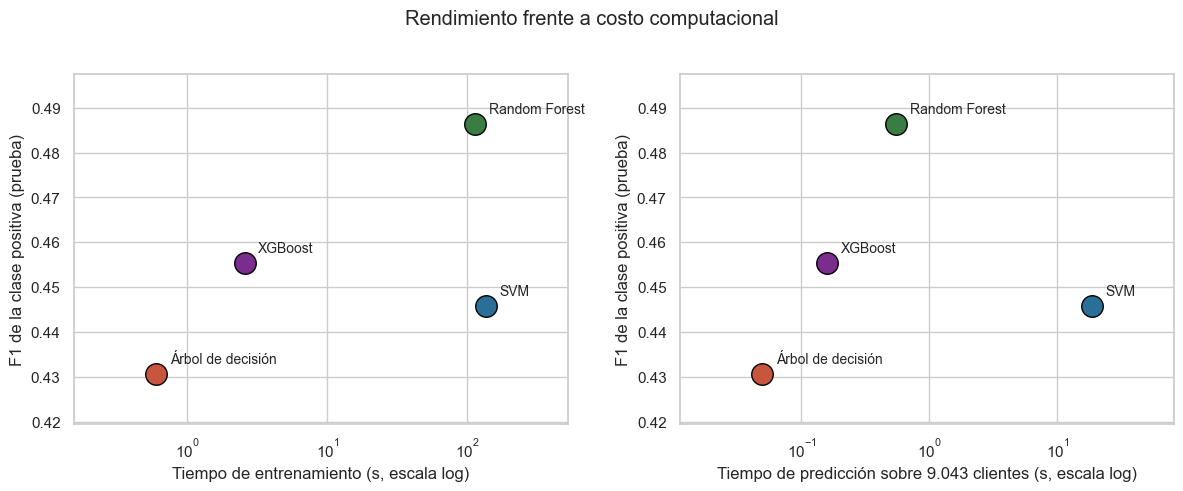

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for eje, columna, titulo in [(ejes[0], "t_entrenamiento_s", "Tiempo de entrenamiento (s, escala log)"),
                             (ejes[1], "t_prediccion_s", "Tiempo de predicción sobre 9.043 clientes (s, escala log)")]:
    for k in modelos:
        eje.scatter(tabla.loc[nombres[k], columna], tabla.loc[nombres[k], "f1"], s=240, color=colores[k],
                    edgecolor="black", zorder=3)
        eje.annotate(nombres[k], (tabla.loc[nombres[k], columna], tabla.loc[nombres[k], "f1"]),
                     textcoords="offset points", xytext=(10, 8), fontsize=10)
    eje.set_xscale("log")
    eje.set_xlabel(titulo)
    eje.set_ylabel("F1 de la clase positiva (prueba)")
    eje.margins(x=0.25, y=0.2)
plt.suptitle("Rendimiento frente a costo computacional", y=1.02)
plt.tight_layout()
guardar("05_rendimiento_vs_costo")
plt.show()

**Lectura.** La esquina deseable es arriba a la izquierda. El árbol está a la izquierda pero abajo,
el Random Forest arriba pero a la derecha y XGBoost en el medio, con un costo de entrenamiento unas cuarenta
veces menor que el bosque y una diferencia de F1 de tres puntos. El SVM queda abajo a la derecha en
ambas figuras, es decir, caro y sin la ventaja de rendimiento que podría justificar el costo.

## Curvas ROC

Grafiqué la curva ROC de cada modelo, que muestra cómo se comporta en todos los umbrales posibles y no
solo en el de 0,5. El área bajo la curva (AUC) resume qué tan bien ordena a los clientes de más a menos
probables, que es justamente lo que necesita una campaña que prioriza llamadas.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_curvas_roc.png


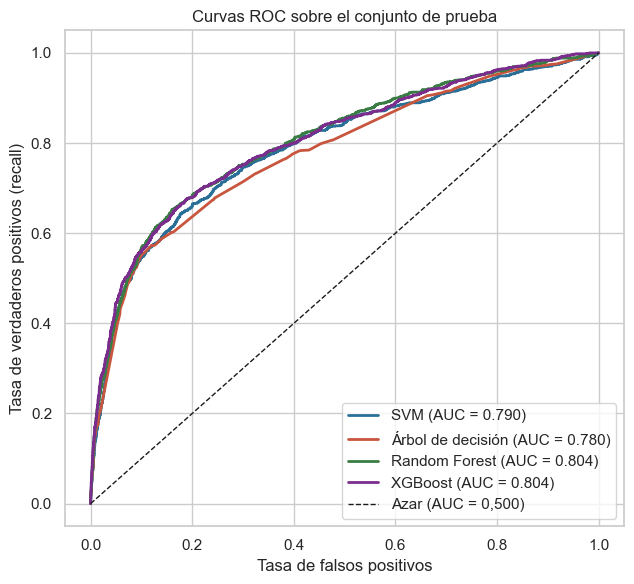

In [5]:
plt.figure(figsize=(6.5, 6))
for k in modelos:
    fpr, tpr, _ = roc_curve(y_test, puntajes[k])
    plt.plot(fpr, tpr, color=colores[k], lw=2, label=f"{nombres[k]} (AUC = {resultados[k]['test']['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0,500)")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curvas ROC sobre el conjunto de prueba")
plt.legend(loc="lower right")
plt.tight_layout()
guardar("05_curvas_roc")
plt.show()

**Lectura.** Las curvas del Random Forest y XGBoost casi se superponen en todo el rango, con AUC de
0,804 los dos. El SVM queda ligeramente por debajo (0,790) y el árbol más abajo (0,780). Los cuatro
están muy por encima del azar, pero ninguno separa las clases con claridad, lo que coincide con la
debilidad de las correlaciones vista en el notebook 02.

## Estabilidad: ¿las diferencias son reales?

Con 9.043 clientes de prueba y solo unos 1.058 contratadores, una diferencia de un par de puntos en F1
puede ser ruido. Grafiqué el intervalo de confianza del 95 % de F1 y de AUC obtenido por bootstrap en el
notebook 04. Si los intervalos de dos modelos se traslapan, el conjunto de prueba no alcanza para afirmar
que uno es mejor que el otro.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_intervalos_bootstrap.png


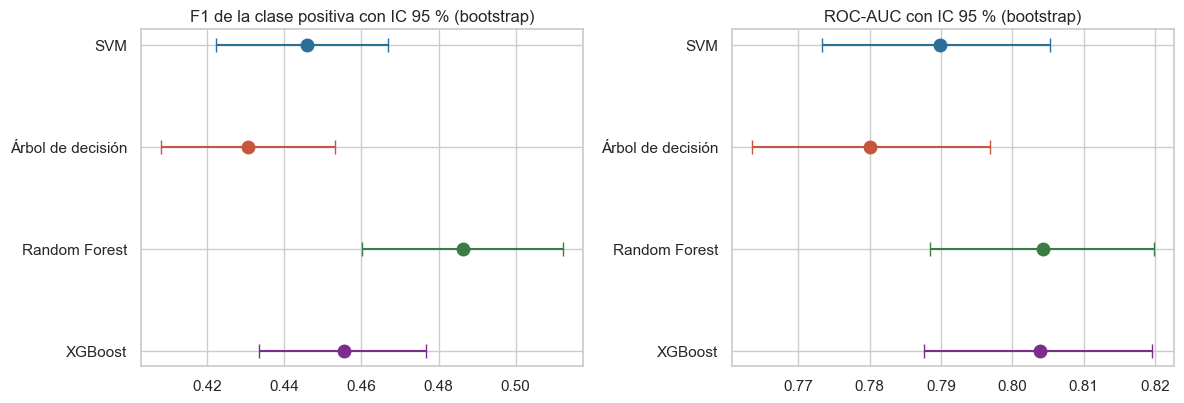

                       F1  F1 IC bajo  F1 IC alto     AUC  AUC IC bajo  AUC IC alto  desv. bootstrap F1
SVM                0.4458      0.4222      0.4670  0.7898       0.7733       0.8052              0.0114
Árbol de decisión  0.4307      0.4079      0.4531  0.7800       0.7634       0.7969              0.0115
Random Forest      0.4863      0.4601      0.5123  0.8043       0.7884       0.8199              0.0130
XGBoost            0.4554      0.4334      0.4768  0.8039       0.7876       0.8196              0.0114


In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
for eje, metrica, clave_ic, titulo in [(ejes[0], "f1", "ic95_f1", "F1 de la clase positiva"),
                                       (ejes[1], "roc_auc", "ic95_auc", "ROC-AUC")]:
    for i, k in enumerate(modelos):
        valor = resultados[k]["test"][metrica]
        bajo, alto = resultados[k][clave_ic]
        eje.errorbar(valor, i, xerr=[[valor - bajo], [alto - valor]], fmt="o", color=colores[k], capsize=5, markersize=9)
    eje.set_yticks(range(len(modelos)))
    eje.set_yticklabels([nombres[k] for k in modelos])
    eje.invert_yaxis()
    eje.set_title(titulo + " con IC 95 % (bootstrap)")
plt.tight_layout()
guardar("05_intervalos_bootstrap")
plt.show()

intervalos = pd.DataFrame({nombres[k]: {"F1": resultados[k]["test"]["f1"], "F1 IC bajo": resultados[k]["ic95_f1"][0],
                                        "F1 IC alto": resultados[k]["ic95_f1"][1], "AUC": resultados[k]["test"]["roc_auc"],
                                        "AUC IC bajo": resultados[k]["ic95_auc"][0], "AUC IC alto": resultados[k]["ic95_auc"][1],
                                        "desv. bootstrap F1": resultados[k]["desv_f1_bootstrap"]} for k in modelos}).T
print(intervalos.round(4).to_string())

**Lectura.** Los intervalos se traslapan bastante. En AUC, los cuatro comparten el rango de 0,788 a
0,797, así que con este conjunto de prueba no se puede afirmar que el Random Forest ordene mejor que
XGBoost, ni que el SVM lo haga peor. En F1, el Random Forest (0,460 a 0,512) y XGBoost (0,433 a 0,477)
también se traslapan, entre 0,460 y 0,477. La ventaja de tres puntos del bosque es plausible, pero no
concluyente. Es una comparación conservadora, porque no empareja las muestras de bootstrap entre
modelos. La estabilidad por bootstrap es parecida en todos (desviación de 0,011 a 0,013).

## Sesgo y varianza

La brecha entre el desempeño sobre entrenamiento y sobre prueba es la lectura práctica del
sesgo-varianza. Un modelo con desempeño bajo en ambos sufre sesgo (es demasiado simple para el
problema), y uno con desempeño alto en entrenamiento y bajo en prueba sufre varianza (memoriza). Medí el
entrenamiento con una muestra de 9.043 filas para que el SVM no tuviera que predecir sobre todo el
conjunto.

                   F1 entrenamiento  F1 prueba  brecha F1  AUC entrenamiento  AUC prueba  brecha AUC
modelo                                                                                              
SVM                          0.4564     0.4458     0.0106             0.7970      0.7898      0.0072
Árbol de decisión            0.4480     0.4307     0.0173             0.8080      0.7800      0.0280
Random Forest                0.6943     0.4863     0.2080             0.9653      0.8043      0.1609
XGBoost                      0.4939     0.4554     0.0386             0.8617      0.8039      0.0578


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_sesgo_varianza.png


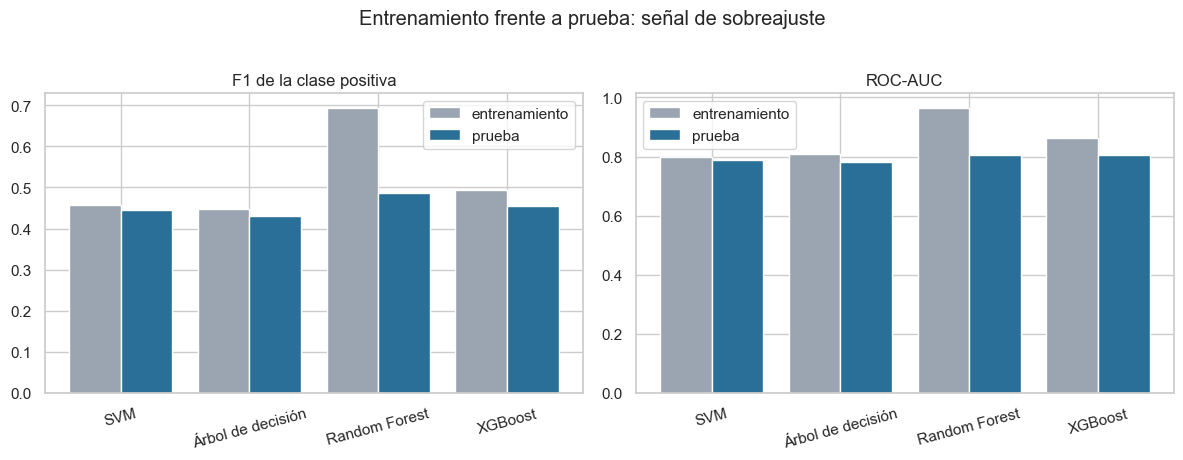

In [7]:
filas = []
for k in modelos:
    r = resultados[k]
    filas.append({"modelo": nombres[k],
                  "F1 entrenamiento": r["train_muestra"]["f1"], "F1 prueba": r["test"]["f1"],
                  "brecha F1": r["train_muestra"]["f1"] - r["test"]["f1"],
                  "AUC entrenamiento": r["train_muestra"]["roc_auc"], "AUC prueba": r["test"]["roc_auc"],
                  "brecha AUC": r["train_muestra"]["roc_auc"] - r["test"]["roc_auc"]})
sesgo_varianza = pd.DataFrame(filas).set_index("modelo")
print(sesgo_varianza.round(4).to_string())

posicion = np.arange(len(modelos))
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for eje, metrica, titulo in [(ejes[0], "F1", "F1 de la clase positiva"), (ejes[1], "AUC", "ROC-AUC")]:
    eje.bar(posicion - 0.2, sesgo_varianza[metrica + " entrenamiento"], width=0.4, label="entrenamiento", color="#9aa5b1")
    eje.bar(posicion + 0.2, sesgo_varianza[metrica + " prueba"], width=0.4, label="prueba", color="#2a6f97")
    eje.set_xticks(posicion)
    eje.set_xticklabels(sesgo_varianza.index, rotation=15)
    eje.set_title(titulo)
    eje.legend()
plt.suptitle("Entrenamiento frente a prueba: señal de sobreajuste", y=1.02)
plt.tight_layout()
guardar("05_sesgo_varianza")
plt.show()

**Lectura.** Los modelos se separan claramente en esta tabla. El SVM tiene la menor brecha (F1 de 0,456
contra 0,446), y su desempeño bajo tanto en entrenamiento como en prueba apunta a un modelo de sesgo
alto, que no logra capturar más señal de la que hay. El árbol podado se comporta igual (brecha de F1 de
0,017). XGBoost tiene una brecha moderada (0,039 de diferencia en F1 y 0,058 en AUC), un modelo
con capacidad de sobra pero frenado por el early stopping. El Random Forest tiene la mayor varianza
(brecha de 0,208 en F1 y 0,161 en AUC). Es un patrón conocido, los árboles profundos del bosque
memorizan casi todo el entrenamiento, y el promedio garantiza que esa memoria no se traduzca en
peores resultados en prueba, pero no la elimina.

## Utilidad para la campaña: captura en el 20 % superior

La métrica que más se parece a la decisión del banco es la captura en el 20 % superior. Si solo se puede
llamar al 20 % de la lista, mide qué fracción de los contratadores queda dentro. Un orden al azar captura
el 20 %. La calculé sobre el puntaje de cada modelo en el conjunto de prueba.

In [8]:
captura = pd.Series({nombres[k]: resultados[k]["captura_top20"] for k in modelos})
print((100 * captura).round(1).astype(str) + " %")
print("\nAzar: 20.0 %")

SVM                  60.0 %
Árbol de decisión    59.5 %
Random Forest        62.6 %
XGBoost              62.3 %
dtype: str

Azar: 20.0 %


**Lectura.** Esta es la cifra más cercana a la decisión del banco. Si solo puede llamar al 20 % de la
lista, el Random Forest captura 62,6 % de los contratadores, XGBoost 62,3 %, el SVM 60,0 % y el árbol
59,5 %. Es unas 3,1 veces lo que lograría una lista al azar (20 %). Las diferencias entre los cuatro
son de pocos puntos, y entre el Random Forest y XGBoost son de 0,3 puntos.

## Criterios de selección

No seleccioné el modelo con una sola métrica. Ordené los cuatro modelos en los criterios que importan
para esta decisión y los leí juntos.

| Criterio | Cómo se mide |
|---|---|
| Rendimiento | F1 de la clase positiva y ROC-AUC en prueba |
| Estabilidad | Desviación estándar de F1 por bootstrap y brecha entre entrenamiento y prueba |
| Costo | Tiempo de entrenamiento y de predicción |
| Interpretabilidad | Criterio cualitativo sobre cuánto se puede explicar a un gerente de campaña |

El orden 1 es el mejor en cada criterio. La interpretabilidad no la calculé, la asigné a partir de cómo
funciona cada familia (un árbol se lee como reglas; un bosque o un boosting se resumen con importancias;
un SVM con kernel RBF casi no se puede explicar).

In [9]:
interpretabilidad = {"SVM": 4, "Arbol": 1, "RandomForest": 3, "XGBoost": 2}

orden = pd.DataFrame({
    "F1": tabla["f1"].rank(ascending=False),
    "AUC": tabla["roc_auc"].rank(ascending=False),
    "estabilidad (desv. bootstrap F1)": pd.Series({nombres[k]: resultados[k]["desv_f1_bootstrap"] for k in modelos}).rank(),
    "brecha F1 (menor mejor)": sesgo_varianza["brecha F1"].abs().rank(),
    "costo de entrenamiento": tabla["t_entrenamiento_s"].rank(),
    "costo de predicción": tabla["t_prediccion_s"].rank(),
    "interpretabilidad": pd.Series({nombres[k]: interpretabilidad[k] for k in modelos}),
}).astype(int)
orden["suma de posiciones"] = orden.sum(axis=1)
print(orden.sort_values("suma de posiciones").to_string())

                   F1  AUC  estabilidad (desv. bootstrap F1)  brecha F1 (menor mejor)  costo de entrenamiento  costo de predicción  interpretabilidad  suma de posiciones
XGBoost             2    2                                 1                        3                       2                    2                  2                  14
Árbol de decisión   4    4                                 3                        2                       1                    1                  1                  16
Random Forest       1    1                                 4                        4                       3                    3                  3                  19
SVM                 3    3                                 2                        1                       4                    4                  4                  21


**Lectura.** XGBoost suma 14 puntos de posición, el árbol 16, el Random Forest 19 y el SVM 21 (menos
es mejor). XGBoost solo es primero en estabilidad por bootstrap, donde las diferencias son mínimas, pero
queda segundo en casi todos los demás criterios, que es lo que lo hace ganador en el balance. El Random Forest gana en rendimiento y
pierde en estabilidad frente al sobreajuste y en costo. El SVM es el más caro y no compensa con
rendimiento. El árbol es el más barato y el más interpretable, pero el que peor rinde.

## Modelo seleccionado: matriz de confusión e importancia de variables

Seleccioné el modelo que mejor equilibra rendimiento, estabilidad y costo según la tabla anterior. Lo
definí en la celda siguiente con una sola variable, de la que dependen la matriz de confusión y la
figura de importancia.

Modelo seleccionado: XGBoost


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_matriz_confusion_mejor.png


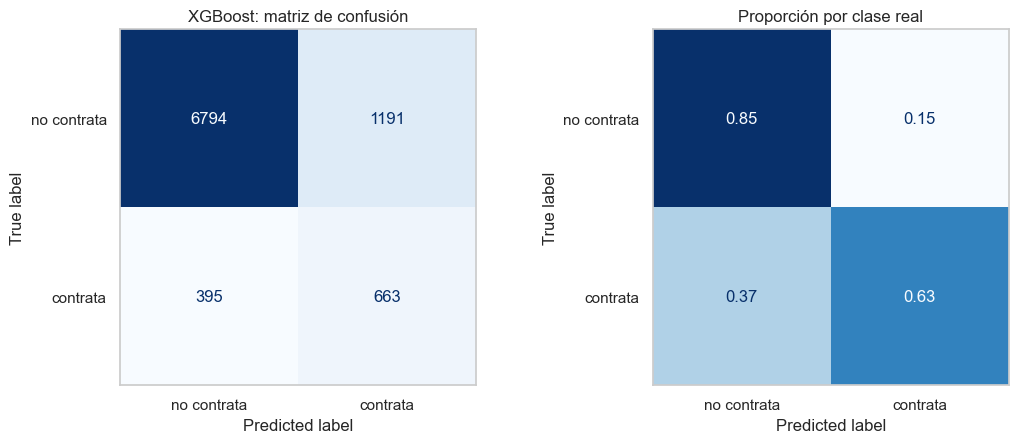

Verdaderos positivos: 663 | Falsos positivos: 1191 | Falsos negativos: 395 | Verdaderos negativos: 6794
De cada 100 llamadas a clientes que el modelo marca como prometedores, 35.8 contratan
El modelo encuentra 62.7 % de los clientes que sí iban a contratar


In [10]:
MEJOR = "XGBoost"
print("Modelo seleccionado:", nombres[MEJOR])

matriz = np.array(resultados[MEJOR]["matriz_confusion"])
pantalla = ConfusionMatrixDisplay(matriz, display_labels=["no contrata", "contrata"])
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.6))
pantalla.plot(ax=ejes[0], cmap="Blues", colorbar=False, values_format="d")
ejes[0].set_title(f"{nombres[MEJOR]}: matriz de confusión")
ejes[0].grid(False)
proporcion = matriz / matriz.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(proporcion, display_labels=["no contrata", "contrata"]).plot(
    ax=ejes[1], cmap="Blues", colorbar=False, values_format=".2f")
ejes[1].set_title("Proporción por clase real")
ejes[1].grid(False)
plt.tight_layout()
guardar("05_matriz_confusion_mejor")
plt.show()

tn, fp, fn, tp = matriz.ravel()
print(f"Verdaderos positivos: {tp} | Falsos positivos: {fp} | Falsos negativos: {fn} | Verdaderos negativos: {tn}")
print(f"De cada 100 llamadas a clientes que el modelo marca como prometedores, {100 * tp / (tp + fp):.1f} contratan")
print(f"El modelo encuentra {100 * tp / (tp + fn):.1f} % de los clientes que sí iban a contratar")

**Lectura.** De los 1.058 clientes de prueba que sí contrataron, el modelo encuentra 663 (62,7 %). Para
lograrlo marca como prometedores a 1.854 clientes, de los cuales contratan 663 (35,8 %), y descarta
correctamente a 6.794. Hay 1.191 llamadas que se harían sin resultado, y 395 contratadores quedan
fuera de la lista. En términos de campaña, una llamada guiada por el modelo tiene 3,1 veces más
probabilidad de terminar en contratación que una llamada elegida al azar (35,8 % contra 11,7 %).

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\05_importancia_variables_mejor.png


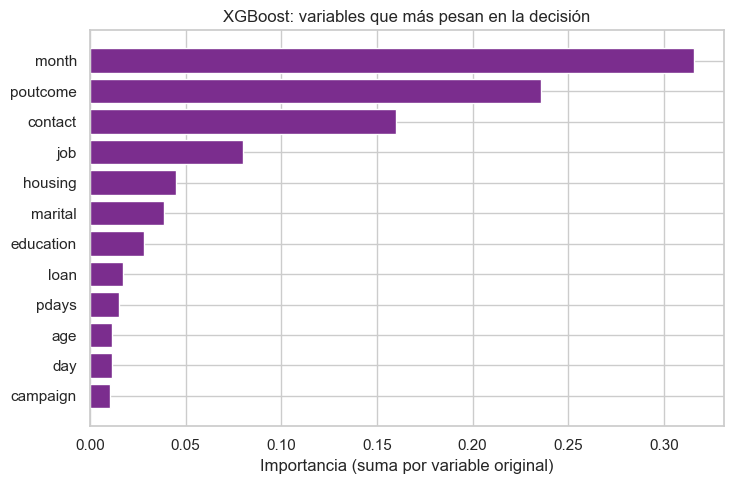

          Árbol de decisión  Random Forest  XGBoost
month                 0.197          0.129    0.316
poutcome              0.265          0.081    0.236
contact               0.136          0.077    0.160
day                   0.100          0.107    0.011
balance               0.064          0.140    0.010
age                   0.049          0.122    0.012
job                   0.006          0.071    0.080
housing               0.063          0.042    0.045
pdays                 0.044          0.049    0.015
campaign              0.033          0.057    0.010


In [11]:
importancia = pd.Series(resultados[MEJOR]["importancia"]).sort_values(ascending=False)
tope = importancia.head(12).sort_values()
plt.figure(figsize=(7.5, 5))
plt.barh(tope.index, tope.values, color=colores[MEJOR])
plt.xlabel("Importancia (suma por variable original)")
plt.title(f"{nombres[MEJOR]}: variables que más pesan en la decisión")
plt.tight_layout()
guardar("05_importancia_variables_mejor")
plt.show()

comparacion_importancia = pd.DataFrame(
    {nombres[k]: pd.Series(resultados[k]["importancia"]) for k in ["Arbol", "RandomForest", "XGBoost"]}).fillna(0)
print(comparacion_importancia.loc[comparacion_importancia.mean(axis=1).sort_values(ascending=False).index].head(10).round(3))

**Lectura.** Las variables más influyentes en XGBoost son `month` (31,6 %), `poutcome` (23,6 %) y
`contact` (16,0 %). Las tres familias de modelos coinciden en que el mes, el resultado de la campaña
anterior y el canal de contacto están entre las más importantes, y difieren en las numéricas, que el
bosque sobrevalora por el efecto del número de umbrales. Una lectura práctica para el banco es que el
momento y el canal de la llamada, y la relación previa con el cliente, pesan más que quién es el
cliente en términos de edad o saldo.

## Cumplimiento de las metas del experimento

En el notebook 01 fijé cinco metas medibles. Verifiqué aquí cada una para los cuatro modelos, con los
resultados sobre el conjunto de prueba. La brecha de sobreajuste la medí con la muestra de entrenamiento
de 9.043 filas del notebook 04.

In [12]:
metas = {
    "ROC-AUC >= 0,75": lambda k: resultados[k]["test"]["roc_auc"] >= 0.75,
    "F1 >= 0,40": lambda k: resultados[k]["test"]["f1"] >= 0.40,
    "Captura top 20 % >= 40 %": lambda k: resultados[k]["captura_top20"] >= 0.40,
    "Brecha de F1 <= 0,10": lambda k: (resultados[k]["train_muestra"]["f1"] - resultados[k]["test"]["f1"]) <= 0.10,
    "Entrena en < 60 s": lambda k: resultados[k]["tiempo_entrenamiento_s"] < 60,
    "Predice en < 1 s": lambda k: resultados[k]["tiempo_prediccion_s"] < 1,
}
cumplimiento = pd.DataFrame({nombres[k]: {meta: ("sí" if prueba(k) else "no") for meta, prueba in metas.items()}
                             for k in modelos}).T
cumplimiento["metas cumplidas"] = (cumplimiento == "sí").sum(axis=1)
print(cumplimiento.to_string())

                  ROC-AUC >= 0,75 F1 >= 0,40 Captura top 20 % >= 40 % Brecha de F1 <= 0,10 Entrena en < 60 s Predice en < 1 s  metas cumplidas
SVM                            sí         sí                       sí                   sí                no               no                4
Árbol de decisión              sí         sí                       sí                   sí                sí               sí                6
Random Forest                  sí         sí                       sí                   no                no               sí                4
XGBoost                        sí         sí                       sí                   sí                sí               sí                6


**Lectura.** Todos los modelos cumplen las metas de rendimiento (AUC, F1 y captura del 20 % superior). Las
diferencias aparecen en el sobreajuste y en el costo. El Random Forest falla la meta de brecha y la de
tiempo de entrenamiento, y el SVM falla las dos de costo. Solo el árbol y XGBoost cumplen las seis metas, y entre los
dos XGBoost rinde mejor (F1 de 0,455 contra 0,431 y AUC de 0,804 contra 0,780).

## Discusión de resultados

**Rendimiento.** El Random Forest es el mejor modelo en F1 (0,486) y en AUC (0,804), y XGBoost lo
iguala en AUC (0,804) y en la captura del 20 % superior (62,3 % contra 62,6 %). El SVM (F1 de 0,446 y AUC
de 0,790) y el árbol (0,431 y 0,780) quedan atrás, aunque los intervalos de bootstrap muestran que las
diferencias en AUC entre los cuatro modelos no son concluyentes con 9.043 clientes de prueba. Que las
cuatro familias alcancen un techo parecido (AUC cerca de 0,8) indica que el límite lo pone la
información disponible y no el algoritmo, algo coherente con las correlaciones débiles del notebook 02.

**La diferencia de F1 entre el Random Forest y XGBoost es en buena parte de punto de operación.** El
bosque marca a menos clientes (precisión de 0,462 y recall de 0,513) y XGBoost marca a más (precisión de
0,358 y recall de 0,627), pero ordenan igual de bien a los clientes. Con un umbral distinto, XGBoost
podría moverse hacia el punto de operación del bosque sin reentrenarse.

**Rendimiento frente a costo.** Aquí las familias se separan mucho. El SVM y el Random Forest
necesitan entre 114 y 135 segundos de entrenamiento con un solo núcleo, XGBoost 2,6 y el árbol 0,6. En
predicción sobre 9.043 clientes, el SVM tarda unos 18 segundos, el Random Forest 0,55, XGBoost 0,16 y
el árbol 0,05. El SVM es el peor del experimento en la relación entre costo y
rendimiento, porque cada predicción compara el cliente con 22.779 vectores de soporte, y su F1 está por
debajo del de dos modelos que cuestan mucho menos. El Random Forest compra tres puntos de F1 sobre XGBoost
con cuarenta veces más tiempo de entrenamiento y unas tres veces más de predicción.

**Sesgo y varianza.** El SVM y el árbol podado tienen brechas pequeñas entre entrenamiento y prueba (0,011
y 0,017 en F1) y un desempeño modesto en ambos conjuntos, lo que los ubica como modelos de sesgo
alto. El Random Forest está en el extremo opuesto, con la mayor varianza (brecha de 0,208 en F1 y de
0,161 en AUC), compensada por el efecto del promedio que mantiene su desempeño en prueba. XGBoost
queda en el medio (brecha de 0,039 en F1 y de 0,058 en AUC) gracias al early stopping y a una tasa de
aprendizaje baja. El árbol sin control fue el caso extremo de varianza (F1 de 1,00 en entrenamiento
y 0,31 en validación), y la poda lo corrigió.

**Mejor modelo.** Seleccioné **XGBoost**. Obtiene el mismo AUC que el Random Forest y casi la misma
captura del 20 % superior, entrena unas cuarenta veces más rápido, predice unas tres veces más rápido y
tiene una brecha de sobreajuste entre tres y cinco veces menor. Su costo es unos tres puntos de F1 con el umbral de
0,5, una diferencia que, como se vio, no es concluyente y es en gran parte un asunto del umbral. En la
suma de posiciones de los criterios gana con 14 puntos. Aun así, el criterio depende de lo que
el banco valore. Si el costo computacional no importara y se quisiera maximizar la precisión de cada
llamada, el Random Forest sería la alternativa. Si se necesitaran reglas que un gerente pueda leer, el
árbol (con 2,5 puntos menos de F1 que XGBoost) es el candidato.

## Conclusiones

**Respuesta al objetivo.** Comparé un SVM, un árbol de decisión, un Random Forest y un XGBoost
para predecir si un cliente contratará un depósito a plazo usando solo información previa a la llamada.
El mejor modelo para este problema es XGBoost. Con el umbral por defecto, de cada 100 clientes que marca
como prometedores contratan 36 (frente a 11,7 de base), encuentra al 62,7 % de los que sí contratarían y
captura al 62,3 % de los contratadores dentro del 20 % de clientes con mayor puntaje, 3,1 veces lo que
lograría el azar. Hace todo eso entrenando en unos segundos.

**Hallazgos sobre los modelos.**

1. El rendimiento máximo es modesto. Ningún modelo pasa de un F1 de 0,49 ni de un AUC de 0,80, y
   los cuatro quedan cerca entre sí. Con las variables disponibles el límite está en los datos, no en el
   algoritmo.
2. El costo sí separa a los modelos. El SVM y el Random Forest cuestan entre cuarenta y doscientas veces más que XGBoost
   y el árbol en entrenamiento, sin ofrecer una ventaja proporcional. El SVM fue el que peor
   relación costo-beneficio tuvo.
3. La ponderación de clases fue la decisión de mayor efecto, y subió el F1 entre 13 y 17 puntos en los
   cuatro modelos.
4. El control del sobreajuste fue necesario en cada familia. El árbol sin límites pasó de 1,00 a 0,31 de
   F1 en validación, el Random Forest necesitó hojas de al menos 3 clientes y XGBoost necesitó early
   stopping.
5. Excluir `duration` fue imprescindible. Esa sola variable alcanza un AUC de 0,808, más que cualquiera de
   los modelos completos.

**Hallazgos sobre el negocio.** El mes de la llamada, el resultado de la campaña anterior y el canal de
contacto son las variables que más pesan. Los clientes con una campaña previa exitosa contratan el 64,7 %
de las veces, y quienes tienen crédito de vivienda contratan menos de la mitad que quienes no lo tienen.

**Limitaciones.**

- El conjunto de prueba tiene solo 1.058 contratadores, y los intervalos de bootstrap muestran que varias
  diferencias entre modelos no son concluyentes. Una validación cruzada repetida sobre todo el conjunto
  daría comparaciones más firmes.
- La partición fue aleatoria, pero los datos son campañas ordenadas en el tiempo (2008 a 2010). Con
  una partición temporal el desempeño probablemente sería menor.
- Hice la búsqueda del SVM sobre 6.000 filas y el mejor `gamma` quedó en el borde de la rejilla.
- Las rejillas fueron modestas, y no se optimizó el umbral de decisión.
- No modelé costos económicos. Asumí que un falso positivo (llamada inútil) y un falso
  negativo (cliente perdido) tienen la misma importancia, algo que en la práctica no ocurre.
- Medí el costo con un solo núcleo y en una sola máquina, y los tiempos absolutos cambian con el
  equipo, aunque no el orden entre modelos.

**Trabajo futuro.**

1. Elegir el umbral con una matriz de costos reales (costo de la llamada frente a ganancia del
   depósito) y no con el 0,5 por defecto.
2. Validar con una partición temporal y con validación cruzada repetida.
3. Probar la versión del conjunto con variables socioeconómicas (`bank-additional`) y variables de
   interacción entre mes, canal y resultado previo.
4. Probar otros modelos de boosting (LightGBM, CatBoost) y calibrar las probabilidades.
5. Aproximar el kernel del SVM (por ejemplo con `Nystroem`) para reducir su costo.